# Análise exploratória: internações por UF (SIH/DATASUS)

Base: `data/processed/internacoes_tratado.csv`, com as internações mensais das 27 UFs de jan/2008 a ago/2026.

Cada seção termina com **o que fazer com isso**. O objetivo é tirar achados que ajudem o gestor a planejar equipes, leitos e estoques.

> As internações (SIH) aproximam a pressão sobre o sistema, mas não medem a fila de UPA/UBS.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

## 1. Dados e qualidade

In [2]:
df = pd.read_csv("../../data/processed/internacoes_tratado.csv", parse_dates=["data"])
print(df.shape, "| período:", df["data"].min().date(), "a", df["data"].max().date())
print("UFs:", df["codigo_uf"].nunique(), "| nulos:", df.isna().sum().sum())
df[df["valor"] == 0]

(6048, 4) | período: 2008-01-01 a 2026-08-01
UFs: 27 | nulos: 0


,codigo_uf,estado,data,valor
244,12,Acre,2009-09-01,0
447,12,Acre,2026-08-01,0
895,14,Roraima,2026-08-01,0


Os zeros acima são `-` do arquivo original, que o tratamento transformou em 0. Em estados que sempre têm internações, isso é dado ausente: viram `NaN`. Também cortamos jul e ago/2026, ainda incompletos para alguns estados (Roraima jul tem 515 contra cerca de 3.000 nos meses vizinhos).

In [3]:
df["valor"] = df["valor"].replace(0, np.nan)
base = df[df["data"] < "2026-07-01"].copy()
brasil = base.groupby("data")["valor"].sum()
print("Meses analisados:", len(brasil), "| último:", brasil.index[-1].date())

Meses analisados: 222 | último: 2026-06-01


## 2. Tendência nacional

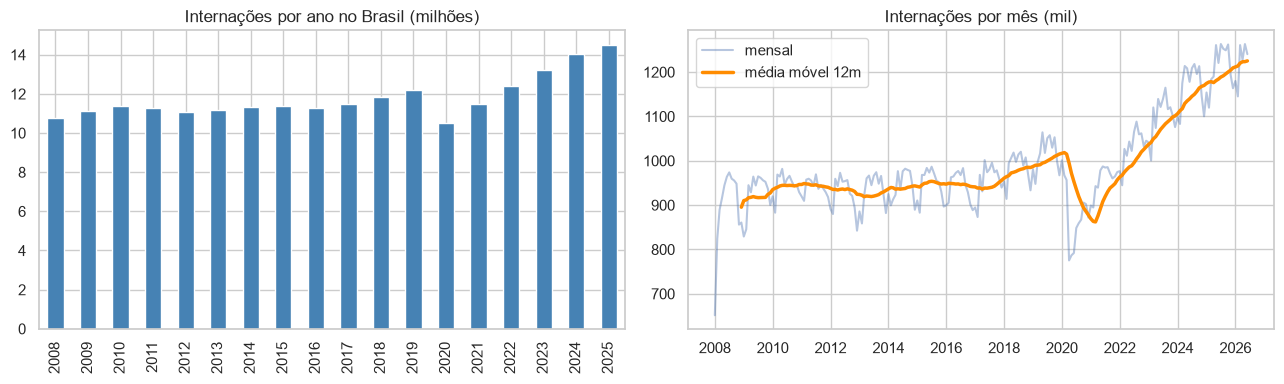

data,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
total (mi),10.74,11.13,11.36,11.28,11.09,11.2,11.32,11.38,11.3,11.47,11.82,12.18,10.53,11.48,12.38,13.22,14.04,14.51
variação (%),NaN,3.60,2.10,-0.70,-1.70,0.9,1.10,0.50,-0.7,1.50,3.00,3.10,-13.50,9.00,7.80,6.80,6.20,3.40


In [4]:
anual = brasil.groupby(brasil.index.year).sum()
anual = anual[anual.index <= 2025]          # só anos fechados
variacao = anual.pct_change() * 100

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
(anual / 1e6).plot.bar(ax=eixos[0], color="steelblue")
eixos[0].set_title("Internações por ano no Brasil (milhões)")
eixos[0].set_xlabel("")

movel = brasil.rolling(12).mean()
eixos[1].plot(brasil.index, brasil / 1e3, alpha=0.4, label="mensal")
eixos[1].plot(movel.index, movel / 1e3, color="darkorange", linewidth=2.5, label="média móvel 12m")
eixos[1].set_title("Internações por mês (mil)")
eixos[1].legend()
plt.tight_layout()
plt.show()

tabela = pd.DataFrame({"total (mi)": (anual / 1e6).round(2), "variação (%)": variacao.round(1)})
tabela.T

In [5]:
cagr = lambda ini, fim: ((anual[fim] / anual[ini]) ** (1 / (fim - ini)) - 1) * 100
print(f"Crescimento médio ao ano 2008-2019: {cagr(2008, 2019):.1f}%")
print(f"Crescimento médio ao ano 2021-2025: {cagr(2021, 2025):.1f}%")
print(f"2025 vs 2019: {(anual[2025] / anual[2019] - 1) * 100:.1f}%")

Crescimento médio ao ano 2008-2019: 1.1%
Crescimento médio ao ano 2021-2025: 6.0%
2025 vs 2019: 19.1%


**O que vemos.** De 2008 a 2019 as internações cresceram devagar, cerca de 1,1% ao ano. Em 2020 caíram 13,5% e, desde 2021, crescem 6,0% ao ano. Em 2025 o total (14,5 milhões) é 19% maior que o de 2019. O avanço de 2025 (+3,4%) foi menor que o de 2022 a 2024 (+6% a +8%).

**O que fazer com isso.** Planejar com base nos anos anteriores a 2020 subestima a necessidade atual. Vale acompanhar 2026 para saber se a desaceleração de 2025 é estabilização ou pausa.

## 3. Pandemia de COVID-19

Maiores quedas mensais (%):
data
2020-04-01   -18.9
2008-11-01    -9.7
2012-12-01    -5.8
2014-12-01    -5.7
Name: valor, dtype: float64

A média móvel de 12 meses voltou ao nível de dez/2019 em 10/2022


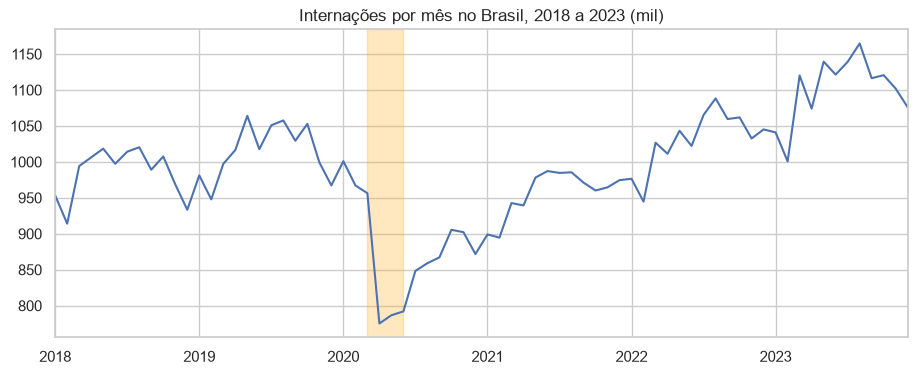

In [6]:
var_mensal = brasil.pct_change() * 100
print("Maiores quedas mensais (%):")
print(var_mensal.nsmallest(4).round(1))

movel_12 = brasil.rolling(12).mean()
nivel_2019 = movel_12["2019-12-01"]
retorno = movel_12[(movel_12.index > "2020-12-01") & (movel_12 >= nivel_2019)].index[0]
print(f"\nA média móvel de 12 meses voltou ao nível de dez/2019 em {retorno:%m/%Y}")

fig, ax = plt.subplots()
(brasil["2018":"2023"] / 1e3).plot(ax=ax)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-01"), color="orange", alpha=0.25)
ax.set_title("Internações por mês no Brasil, 2018 a 2023 (mil)")
ax.set_xlabel("")
plt.show()

**O que vemos.** Abril de 2020 teve a maior queda mensal da série (-18,9%). A média móvel de 12 meses só voltou ao nível de dez/2019 em out/2022.

**O que fazer com isso.** Tratar 2020 e 2021 como período atípico em médias, metas e modelos, para a queda não virar o "normal" do planejamento.

## 4. Sazonalidade nacional

Para medir a sazonalidade, dividimos cada mês pela média do próprio ano e tiramos a média entre os anos de 2012 a 2025. Ficam de fora 2020 e 2021 (pandemia) e anos incompletos. Valor 1,00 é um mês típico.

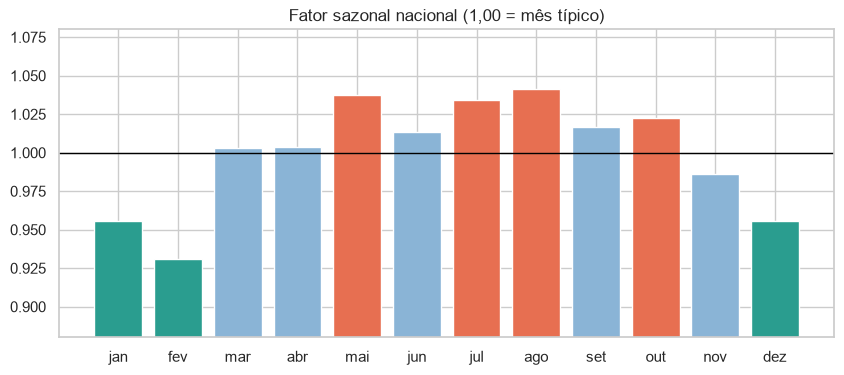

{'jan': -4.5, 'fev': -6.9, 'mar': 0.3, 'abr': 0.4, 'mai': 3.7, 'jun': 1.3, 'jul': 3.4, 'ago': 4.1, 'set': 1.7, 'out': 2.2, 'nov': -1.4, 'dez': -4.5}


In [7]:
def fator_sazonal(serie):
    serie = serie[(serie.index.year >= 2012) & ~serie.index.year.isin([2020, 2021])]
    fechados = serie.groupby(serie.index.year).count().loc[lambda c: c == 12].index
    serie = serie[serie.index.year.isin(fechados)]
    relativa = serie / serie.groupby(serie.index.year).transform("mean")
    return relativa.groupby(relativa.index.month).mean()


saz_br = fator_sazonal(brasil)

fig, ax = plt.subplots(figsize=(10, 4))
cores = ["#e76f51" if v >= 1.02 else "#2a9d8f" if v <= 0.97 else "#8ab4d6" for v in saz_br.values]
ax.bar(MESES, saz_br.values, color=cores)
ax.axhline(1, color="black", linewidth=1)
ax.set_ylim(0.88, 1.08)
ax.set_title("Fator sazonal nacional (1,00 = mês típico)")
plt.show()

print((saz_br.sub(1).mul(100)).round(1).rename(dict(zip(range(1, 13), MESES))).to_dict())

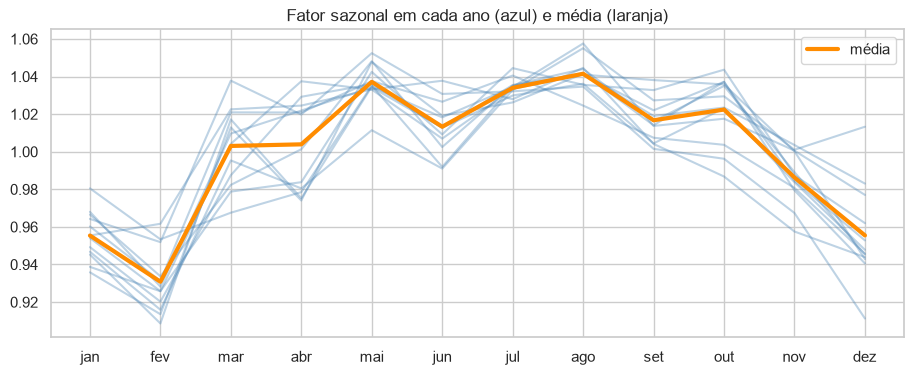

In [8]:
# o padrão se repete ano a ano? fator de cada mês, ano a ano
anos = [a for a in range(2012, 2026) if a not in (2020, 2021)]
def fator_do_ano(ano):
    s = brasil[str(ano)]
    relativo = s / s.mean()
    relativo.index = relativo.index.month
    return relativo


por_ano = pd.DataFrame({a: fator_do_ano(a) for a in anos})

fig, ax = plt.subplots()
for a in anos:
    ax.plot(MESES, por_ano[a].values, color="steelblue", alpha=0.35)
ax.plot(MESES, saz_br.values, color="darkorange", linewidth=3, label="média")
ax.set_title("Fator sazonal em cada ano (azul) e média (laranja)")
ax.legend()
plt.show()

**O que vemos.** Há um padrão que se repete todo ano (gráfico anual). Os meses mais pesados são ago (+4,1% sobre a média do ano), mai (+3,7%), jul (+3,4%) e out (+2,2%). Os mais leves são fev (-6,9%), jan e dez (-4,5%). Entre fev e ago a diferença é de cerca de 11 pontos percentuais (fevereiro também tem menos dias).

**O que fazer com isso.**
- Reforçar escalas, leitos e estoques de maio a outubro.
- Aproveitar dez a fev para férias, manutenção e reposição.
- Comparar um mês com o mesmo mês do ano anterior, e não com o mês anterior, para não confundir sazonalidade com tendência.

## 5. Sazonalidade por UF

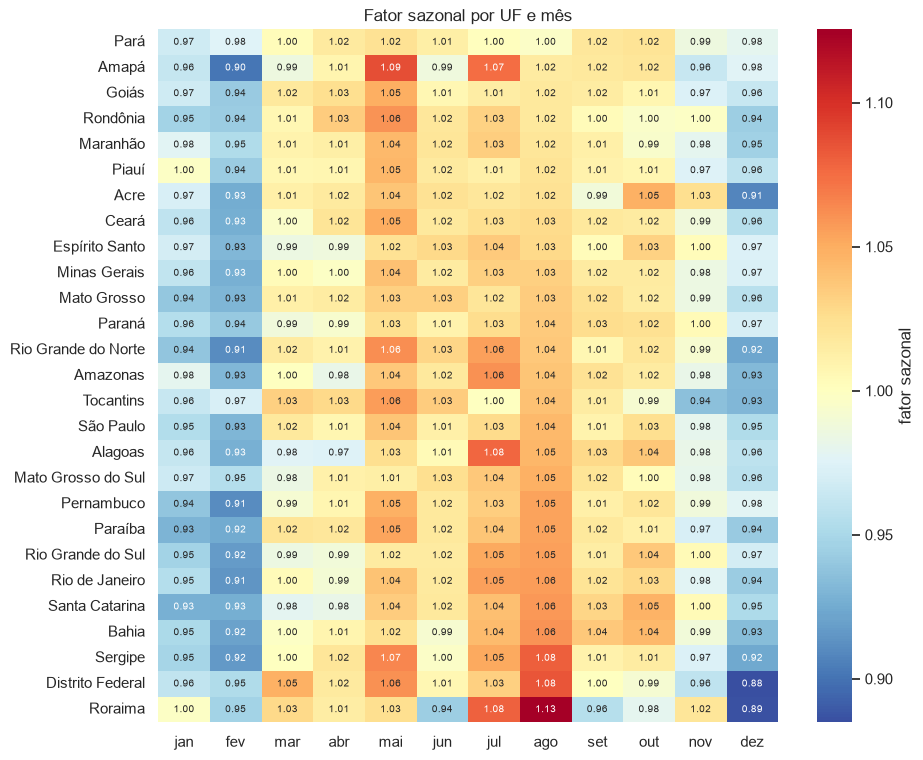

In [9]:
matriz = pd.DataFrame({
    estado: fator_sazonal(g.set_index("data")["valor"].dropna())
    for estado, g in base.groupby("estado")
}).T
matriz.columns = MESES

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(matriz.sort_values("ago"), cmap="RdYlBu_r", center=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "fator sazonal"}, ax=ax)
ax.set_title("Fator sazonal por UF e mês")
ax.set_ylabel("")
plt.show()

In [10]:
resumo = pd.DataFrame({
    "mês de pico": matriz.idxmax(axis=1),
    "mês de vale": matriz.idxmin(axis=1),
    "amplitude (pp)": ((matriz.max(axis=1) - matriz.min(axis=1)) * 100).round(1),
}).sort_values("amplitude (pp)", ascending=False)
print(resumo["mês de pico"].value_counts().to_dict(), "(pico)")
print(resumo["mês de vale"].value_counts().to_dict(), "(vale)")
resumo

{'ago': 13, 'mai': 10, 'jul': 3, 'out': 1} (pico)
{'fev': 21, 'dez': 5, 'jan': 1} (vale)


,mês de pico,mês de vale,amplitude (pp)
Roraima,ago,dez,23.9
Distrito Federal,ago,dez,19.9
Amapá,mai,fev,18.6
Sergipe,ago,fev,16.5
Rio Grande do Norte,mai,fev,15.1
Alagoas,jul,fev,15.0
Pernambuco,ago,fev,14.4
Rio de Janeiro,ago,fev,14.2
Acre,out,dez,14.0
Bahia,ago,fev,13.9


**O que vemos.** Agosto é o mês de pico em 13 UFs e maio em 10. Fevereiro é o vale em 21 UFs e dezembro em 5. A amplitude sazonal varia bastante: Roraima (23,9 pp, série ruidosa), Distrito Federal (19,9) e Amapá (18,6) no topo, e Pará (5,7) na base.

**O que fazer com isso.** Usar um calendário sazonal por estado, e não um único para o país. Estados de maior amplitude precisam de escala mais flexível; no Pará o ano é mais estável.

## 6. Crescimento por UF

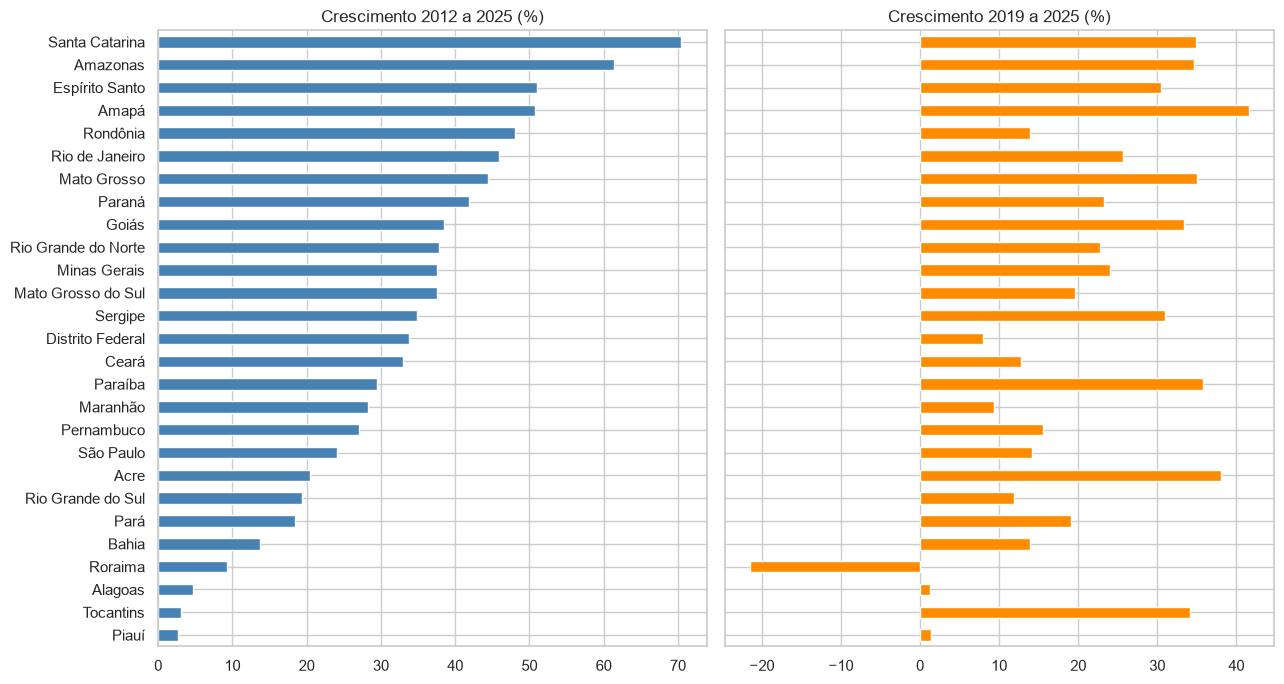

,2012 a 2025,2019 a 2025,2019 a 2020
estado,,,
Piauí,2.7,1.4,-17.6
Tocantins,3.1,34.1,-5.0
Alagoas,4.7,1.2,-15.5
Roraima,9.3,-21.5,-11.4
Bahia,13.7,13.9,-16.7
Pará,18.4,19.1,-10.6
Rio Grande do Sul,19.3,11.9,-12.4
Acre,20.5,38.0,-3.3
São Paulo,24.1,14.2,-13.2


In [11]:
totais = (base.dropna(subset=["valor"])
          .groupby(["estado", base["data"].dt.year])["valor"].agg(["sum", "count"]))
totais = totais[totais["count"] == 12]["sum"].unstack()

cresc = pd.DataFrame({
    "2012 a 2025": (totais[2025] / totais[2012] - 1) * 100,
    "2019 a 2025": (totais[2025] / totais[2019] - 1) * 100,
    "2019 a 2020": (totais[2020] / totais[2019] - 1) * 100,
}).round(1).sort_values("2012 a 2025")

fig, eixos = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
cresc["2012 a 2025"].plot.barh(ax=eixos[0], color="steelblue")
eixos[0].set_title("Crescimento 2012 a 2025 (%)")
cresc["2019 a 2025"].plot.barh(ax=eixos[1], color="darkorange")
eixos[1].set_title("Crescimento 2019 a 2025 (%)")
for ax in eixos:
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

cresc

**O que vemos.** Desde 2012, Piauí (+2,7%), Tocantins (+3,1%) e Alagoas (+4,7%) quase não cresceram, enquanto Santa Catarina (+70,4%) e Amazonas (+61,4%) cresceram muito. De 2019 a 2025 os destaques são Amapá (+41,6%), Acre (+38,0%), Paraíba (+35,8%), Santa Catarina (+34,9%) e Amazonas (+34,6%). Roraima caiu 21,5%, mas a série tem problemas de qualidade.

**O que fazer com isso.** Estados de crescimento acelerado devem ter prioridade para ampliar capacidade. Estagnação pode indicar oferta saturada ou subnotificação, e vale cruzar com a população (IBGE) antes de concluir.

## 7. Concentração do volume

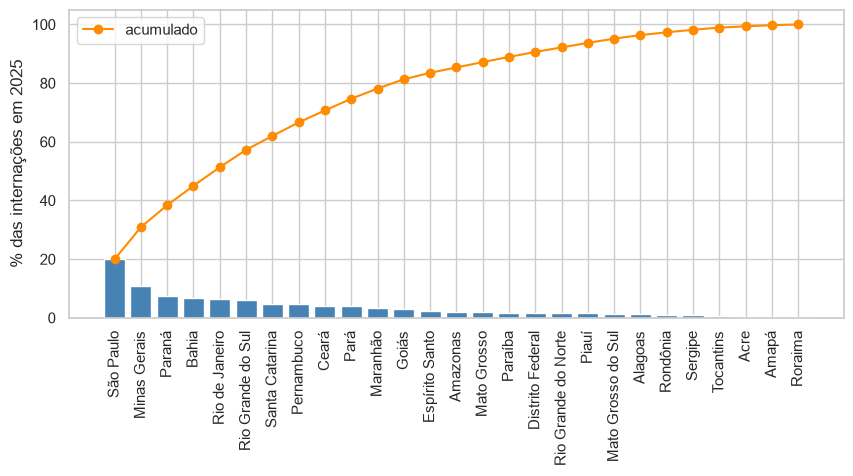

Cinco maiores: {'São Paulo': 20.0, 'Minas Gerais': 11.0, 'Paraná': 7.5, 'Bahia': 6.6, 'Rio de Janeiro': 6.3} | soma: 51.3
Dez maiores somam: 74.7 %


In [12]:
vol_2025 = totais[2025].sort_values(ascending=False)
particip = vol_2025 / vol_2025.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(particip.index, particip.values, color="steelblue")
ax.plot(particip.index, particip.cumsum().values, color="darkorange", marker="o", label="acumulado")
ax.set_ylabel("% das internações em 2025")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.show()

print("Cinco maiores:", particip.head(5).round(1).to_dict(), "| soma:", round(particip.head(5).sum(), 1))
print("Dez maiores somam:", round(particip.head(10).sum(), 1), "%")

**O que vemos.** São Paulo responde por 20% das internações, os cinco maiores estados (SP, MG, PR, BA, RJ) por 51,3% e os dez maiores por 74,7%.

**O que fazer com isso.** Um pequeno erro percentual nos estados grandes pesa muito em volume, então vale priorizar monitoramento e modelo nos dez maiores. Os estados pequenos exigem um olhar próprio, com margens maiores.

## 8. Volatilidade e previsibilidade

Quanto o volume oscila de um mês para outro em cada UF (desvio-padrão da variação mensal, fora de 2020). Estados mais voláteis são mais difíceis de prever.

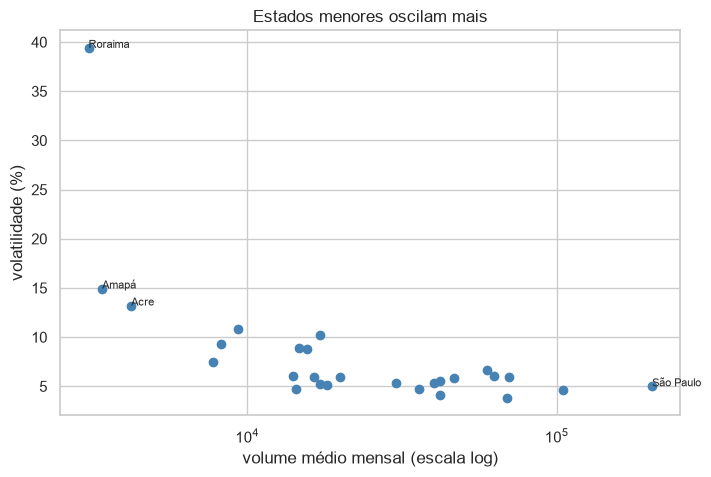

Correlação (log do volume x volatilidade): -0.63


,volume médio mensal,volatilidade (%)
estado,,
Roraima,3070.7,39.4
Amapá,3398.5,14.9
Acre,4217.0,13.2
Rondônia,9362.4,10.8
Distrito Federal,17183.1,10.2
Sergipe,8226.4,9.3
Rio Grande do Norte,14736.0,8.9
Amazonas,15598.2,8.8


In [13]:
variacao_uf = (base[base["data"].dt.year != 2020]
               .pivot(index="data", columns="estado", values="valor")
               .pct_change() * 100)
volatilidade = variacao_uf.std()

dados = pd.DataFrame({
    "volume médio mensal": base.groupby("estado")["valor"].mean(),
    "volatilidade (%)": volatilidade,
})

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(dados["volume médio mensal"], dados["volatilidade (%)"], color="steelblue")
ax.set_xscale("log")
for estado, linha in dados.iterrows():
    if linha["volatilidade (%)"] > 12 or linha["volume médio mensal"] > 150_000:
        ax.annotate(estado, (linha["volume médio mensal"], linha["volatilidade (%)"]), fontsize=8)
ax.set_xlabel("volume médio mensal (escala log)")
ax.set_ylabel("volatilidade (%)")
ax.set_title("Estados menores oscilam mais")
plt.show()

print("Correlação (log do volume x volatilidade):",
      round(np.corrcoef(np.log(dados["volume médio mensal"]), dados["volatilidade (%)"])[0, 1], 2))
dados.sort_values("volatilidade (%)", ascending=False).round(1).head(8)

**O que vemos.** Quanto menor o estado, mais o volume oscila de um mês para o outro (correlação de -0,63 entre o log do volume e a volatilidade). Roraima (39%), Amapá (15%) e Acre (13%) oscilam mais.

**O que fazer com isso.** As previsões de estados pequenos têm faixa de incerteza maior e devem ser lidas com margem. É importante acompanhar o erro por UF, e não só o total.

## Resumo: o que levar para a decisão

| tema | achado | ação |
|---|---|---|
| Tendência | +6% ao ano desde 2021, 19% acima de 2019 | planejar com a base atual, não a pré-2020 |
| Sazonalidade | pico em mai, jul, ago e out; vale em fev, dez e jan | reforço de escalas e estoques de mai a out |
| Por estado | amplitude de 6 a 24 pp | calendário sazonal por UF |
| Crescimento | Amapá, Acre, Paraíba, SC e AM crescem mais | priorizar capacidade nesses estados |
| Concentração | 10 UFs = 75% das internações | foco de monitoramento nos maiores |
| Previsibilidade | estados pequenos oscilam mais | usar faixas de incerteza maiores |

**Limites.** Internações do SIH aproximam a pressão sobre o sistema, mas não medem a fila de UPA/UBS. Alguns meses recentes estão incompletos, e as séries de Roraima e Acre têm problemas de qualidade.